# Burst to Flex: proof-of-work demo

This notebook re-runs small pieces of the project live and checks them against the stored results the paper uses.
It **only reads** the existing data, model checkpoint, prediction files, results and paper files. It never writes to them.

1. **Data**: the cleaned Microsoft Philly job log.
2. **Transformer live**: the trained model predicts 5 randomly drawn test jobs, compared with the stored predictors.
3. **Simulator live**: one grid event re-simulated from scratch, compared with the stored E1 result row.
4. **Checks**: the test suites, the prediction-file checker and the simulator's baseline check (Table I).
5. **Reproducibility**: where the paper's numbers come from.

How to run it: see `demo/README.md`.

In [1]:
import subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

T0 = time.perf_counter()
ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists():          # the notebook lives in demo/; find the repo root
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "ml"), str(ROOT / "backend")]
DATA, PRED = ROOT / "data" / "processed", ROOT / "predictions"
pd.set_option("display.width", 160)
print("repo root:", ROOT)

repo root: C:\AA_STUDY\College Materials\Sem-7\MINOR PROJECT\smart-scheduler-chooser


## 1. Data: the Philly job log

The Microsoft Philly trace is a public log of about 117,000 deep-learning jobs on a shared GPU cluster (Aug-Dec 2017).
Track 1 cleaned it into `data/processed/philly_jobs.parquet`, one row per job. Each job ends as **Pass**, **Failed** or **Killed** (cancelled).
The chart shows why this matters for the paper: Failed and Killed jobs are a minority of jobs but use most of the GPU-hours.
Holding back such a job during a grid event costs little useful work.
The model is tested only on jobs submitted in the test window.
(These counts are over the whole log. The paper's Section 2 uses only the simulated test-window jobs, so its shares differ.)

total jobs: 117,325
test window (2017-11-15 to 2017-12-16, end exclusive): 27,022 jobs submitted


,jobs,gpu_hours,jobs_%,gpu_hours_%
status,,,,
Pass,84358,1116547.6,71.9,33.1
Failed,18633,1137889.4,15.9,33.8
Killed,14334,1114169.0,12.2,33.1


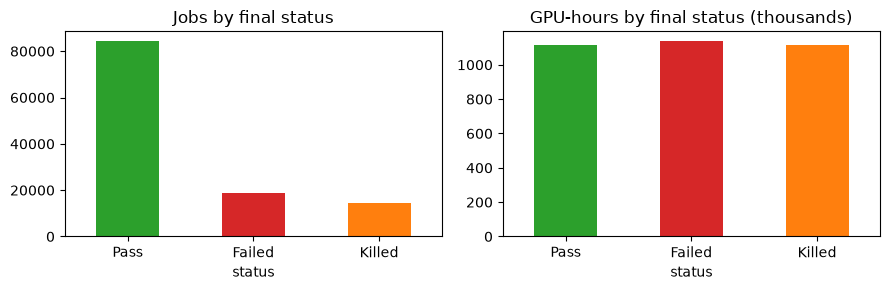

In [2]:
import config                                     # ml/config.py: split dates and the seed
jobs = pd.read_parquet(DATA / "philly_jobs.parquet")
jobs["gpu_h"] = jobs["num_gpus"] * jobs["wall_s"].fillna(0).astype(float) / 3600
t0, t1 = (int(pd.Timestamp(d, tz="UTC").timestamp()) for d in (config.TEST_START, config.TEST_END))
in_test = jobs["submit_time"].between(t0, t1 - 1)

by = jobs.groupby("status").agg(jobs=("job_id", "size"), gpu_hours=("gpu_h", "sum")).reindex(["Pass", "Failed", "Killed"])
by["jobs_%"] = 100 * by["jobs"] / by["jobs"].sum()
by["gpu_hours_%"] = 100 * by["gpu_hours"] / by["gpu_hours"].sum()
print(f"total jobs: {len(jobs):,}")
print(f"test window ({config.TEST_START} to {config.TEST_END}, end exclusive): {in_test.sum():,} jobs submitted")
display(by.round(1))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
colors = ["tab:green", "tab:red", "tab:orange"]
by["jobs"].plot.bar(ax=ax[0], color=colors, title="Jobs by final status", rot=0)
(by["gpu_hours"] / 1e3).plot.bar(ax=ax[1], color=colors, title="GPU-hours by final status (thousands)", rot=0)
plt.tight_layout(); plt.show()

## 2. Transformer live: predictions for 5 random test jobs

The transformer reads a job's owner's last (up to 32) finished jobs plus the current job.
It predicts the **remaining runtime** as three quantiles (p10, p50, p90) and the chance the job will **fail** (p_fail).
Here we load the best saved checkpoint (`runs/tf_v1/best.pt`) and run it now, on the CPU, on 5 test examples.
The examples are drawn with a fixed, printed seed (`ml/config.py` SEED), so nobody chose them by hand.
Next to the live predictions we show the true outcome and the stored rows of two other predictors for the same job and elapsed time.
`last2` is the classic "average of the user's last two jobs" rule; `lightgbm` is a gradient-boosted-tree baseline.
The last column checks that the live output equals the stored `predictions/transformer.csv` row the simulator used.
Expect about 1e-6: the file was written on the GPU, this run is on the CPU, and float32 rounds slightly differently.

In [3]:
import warnings
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
import model as M
from predict import predict_frame

ex = pd.read_parquet(DATA / "ml_examples.parquet")
SEED = config.SEED
pick = ex[ex["split"] == "test"].sample(5, random_state=SEED).reset_index(drop=True)
print(f"seed = {SEED}; 5 of {(ex['split'] == 'test').sum():,} test examples")

ckpt = torch.load(ROOT / "runs" / "tf_v1" / "best.pt", map_location="cpu")
net = M.HistoryTransformer(n_vc=ckpt["n_vc"])
net.load_state_dict(ckpt["state_dict"])
live = predict_frame(net, pick, jobs.drop(columns="gpu_h"), ckpt["vc_map"], torch.device("cpu"))

keys = pick[["job_id", "elapsed_s"]]
def stored(name):
    df = pd.read_csv(PRED / f"{name}.csv", dtype={"job_id": str})
    return keys.merge(df, on=["job_id", "elapsed_s"], how="left")
last2, lgbm, tf_csv = stored("last2"), stored("lightgbm"), stored("transformer")

h = lambda s: (s.astype(float) / 3600).round(2)
table = pd.DataFrame({
    "job": pick["job_id"].str[-12:], "elapsed_h": h(pick["elapsed_s"]), "history": pick["hist_count"],
    "tf_p10_h": h(live["rt_p10_s"]), "tf_p50_h": h(live["rt_p50_s"]), "tf_p90_h": h(live["rt_p90_s"]),
    "tf_p_fail": live["p_fail"].astype(float).round(3),
    "true_rem_h": h(pick["remaining_s"]), "true_status": pick["status"],
    "last2_p50_h": h(last2["rt_p50_s"]), "last2_p_fail": last2["p_fail"].round(3),
    "lgbm_p50_h": h(lgbm["rt_p50_s"]), "lgbm_p_fail": lgbm["p_fail"].round(3),
})
cols = ["rt_p10_s", "rt_p50_s", "rt_p90_s", "p_fail", "p_cancel"]
table["live_vs_csv_max_rel_diff"] = ((live[cols] - tf_csv[cols]).abs() / tf_csv[cols].abs().clip(lower=1e-9)).max(axis=1)
display(table)

seed = 0; 5 of 71,806 test examples


,job,elapsed_h,history,tf_p10_h,tf_p50_h,tf_p90_h,tf_p_fail,true_rem_h,true_status,last2_p50_h,last2_p_fail,lgbm_p50_h,lgbm_p_fail,live_vs_csv_max_rel_diff
0,8684064_1722,0.00,32,0.94,1.68,2.70,0.005,1.60,Pass,1.52,0.000,1.19,0.023,1.046239e-06
1,6184019_0992,0.00,32,0.02,1.69,107.76,0.662,0.02,Killed,0.02,0.406,0.48,0.280,9.598505e-07
2,6184019_2505,1.00,32,3.20,72.63,521.87,0.504,57.85,Killed,0.02,0.281,28.93,0.207,1.942802e-06
3,6184019_1563,0.00,32,0.06,1.93,35.36,0.118,0.12,Killed,9.93,0.219,1.32,0.276,9.764563e-07
4,0382012_3025,0.17,32,0.05,0.09,0.26,0.081,2.19,Pass,0.02,0.531,0.27,0.279,1.154023e-06


Over the whole test split, these are the saved T4 metrics (`ml/results/predictor_metrics.csv`, computed once, never tuned on test).
Lower is better for pinball (runtime quantile error) and log-loss (status); coverage_p10_p90 should be near 0.80; higher AUROC is better.

In [4]:
m = pd.read_csv(ROOT / "ml" / "results" / "predictor_metrics.csv")
display(m[m["elapsed_s"].astype(str) == "all"].drop(columns="elapsed_s").set_index("predictor").round(3))

,n,pinball,mae_p50_min,coverage_p10_p90,logloss,auroc_failed,brier_pfail
predictor,,,,,,,
last2,71806,1.034,52.608,0.080,2.343,0.772,0.155
gbdt,71806,0.419,43.495,0.779,0.682,0.797,0.134
lightgbm,71806,0.426,44.978,0.802,0.678,0.800,0.133
transformer,71806,0.442,65.168,0.778,0.789,0.805,0.138
oracle,71806,0.000,0.000,1.000,0.000,1.000,0.000
prior,71806,NaN,NaN,NaN,0.888,0.542,0.179


## 3. Simulator live: one grid event, re-run from scratch

The grid asks the cluster to cut its power by **20% for 2 hours** (the paper's default event).
We take the first event of that cell from the same event list E1 uses.
We simulate the trace up to the event start and copy the cluster state there (the *snapshot*).
From that one snapshot we run four futures:
- **baseline**: no event;
- **delay-only**: pause running jobs;
- **burst-only**: move running jobs to rented cloud GPUs;
- **mix-p90**: the paper's controller, mixing pausing, power capping and bursting, with the transformer's p90 runtime.

All runs use the transformer predictions with the hold-beyond-grid rule.
The target P* is 80% of the baseline's mean power during the event. The cost is $ per MWh shed (cloud bill + delay cost, w_f = 0).
At the end we compare every number with the stored row in `results/e1/runs.csv`.

In [5]:
import dataclasses
from flex.cloud import Cloud
from flex.engine import Engine
from flex.experiments import DEFAULT_EVENT, cell, load_setup
from flex.metrics import compliance
from flex.models import load_config
from flex.policies import run_policy, world_from_config
from flex.power import PowerTracker
from flex.predictions import load_predictions
from flex.paired import run_base

t_sim = time.perf_counter()
cfg = load_config()
cfg, sim_jobs, pool, events = load_setup(cfg, "philly", quick=False)
ev = cell(events, *DEFAULT_EVENT)[0]
print(ev)
tf = load_predictions(PRED / "transformer.csv")
tf.lookup_rule, tf.missing_pred = cfg["lookup_rule"], cfg["missing_pred"]
print("lookup rule:", tf.lookup_rule)
world = world_from_config(cfg, tf)

eng = Engine(sim_jobs, pool, check_every=cfg["check_every"], cloud=Cloud(world.cloud))
eng.run_until(ev.t_start - 3600)                  # run the trace up to 1 h before the event ...
pre = PowerTracker(world.params); pre.attach(eng) # ... record baseline power for that hour ...
eng.run_until(ev.t_start)
eng.on_event = None
snap = eng.snapshot()                             # ... and copy the state at the event start

base = run_base(snap, ev, world.params, world.h_after_s)
runs, rows = {"baseline": base}, {}
for label, name, w in [("delay-only", "delay", world), ("burst-only", "burst", world),
                       ("mix-p90", "mix", dataclasses.replace(world, cost_quantile="p90"))]:
    rows[label], _, runs[label] = run_policy(snap, ev, name, w, "transformer", "predictor", cfg["seed"], base, return_runs=True)
print(f"simulation: {time.perf_counter() - t_sim:.0f} s")

pool G = 2300 GPUs (philly.pool_gpus = auto); installed = 2892


Philly: 37394 jobs, pool G = 2300 (installed 2892), 90 events; carry-over 643 jobs, truncated 0
Event(event_id='d2h_c20_0', t_start=963000, t_end=970200, duration_h=2, cut=0.2)


lookup rule: hold_beyond_grid


simulation: 22 s


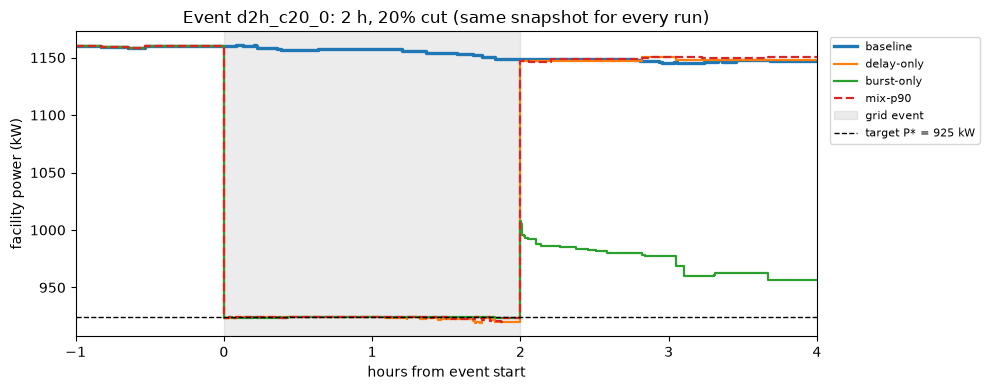

In [6]:
lo, hi = ev.t_start - 3600, ev.t_end + 7200
p_star = rows["delay-only"]["target_kw"]
fig, ax = plt.subplots(figsize=(10, 4))
style = {"baseline": dict(lw=2.4), "delay-only": dict(lw=1.6), "burst-only": dict(lw=1.6), "mix-p90": dict(lw=1.6, ls="--")}
for label, r in runs.items():
    steps = [s for s in pre.steps if s[0] < ev.t_start] + [s for s in r.tracker.steps if s[0] <= hi]
    t = [(max(s[0], lo) - ev.t_start) / 3600 for s in steps] + [(hi - ev.t_start) / 3600]
    p = [s[1] for s in steps] + [steps[-1][1]]
    ax.step(t, p, where="post", label=label, **style[label])
ax.axvspan(0, (ev.t_end - ev.t_start) / 3600, color="grey", alpha=0.15, label="grid event")
ax.axhline(p_star, color="black", ls="--", lw=1, label=f"target P* = {p_star:,.0f} kW")
ax.set_xlim((lo - ev.t_start) / 3600, (hi - ev.t_start) / 3600)
ax.set_xlabel("hours from event start"); ax.set_ylabel("facility power (kW)")
ax.set_title(f"Event {ev.event_id}: {ev.duration_h} h, {ev.cut:.0%} cut (same snapshot for every run)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()

All three policies bring power down to P* within the event. After the event, delay-only and mix-p90 return to the baseline level.
Burst-only stays lower, because the moved jobs finish in the cloud. Its cost is the cloud bill, which the table below shows.

In [7]:
COLS = ["shed_mwh", "compliance", "cloud_usd", "delay_usd", "usd_per_mwh"]
def view(r):
    return {"shed_mwh": r["shed_mwh"], "compliance": r["compliance"], "cloud_usd": r["cloud_usd"],
            "delay_usd": r["cost_usd"] - r["cloud_usd"], "usd_per_mwh": r["usd_per_mwh"]}

live_t = pd.DataFrame({k: view(r) for k, r in rows.items()}).T[COLS]
base_row = {"shed_mwh": 0.0, "compliance": compliance(base.tracker, ev.t_start, ev.t_end, p_star),
            "cloud_usd": 0.0, "delay_usd": 0.0, "usd_per_mwh": float("nan")}
print("LIVE (this notebook)")
display(pd.concat([pd.DataFrame({"baseline": base_row}).T, live_t]).round(3))

st = pd.read_csv(ROOT / "results" / "e1" / "runs.csv", dtype={"setting": str})
st = st[(st["event_id"] == ev.event_id) & (st["predictor"] == "transformer")].fillna({"setting": ""})
pick_row = {"delay-only": ("delay", ""), "burst-only": ("burst", ""), "mix-p90": ("mix", "cq=p90")}
stored_t = pd.DataFrame({k: view(st[(st["policy"] == p) & (st["setting"] == s)].iloc[0]) for k, (p, s) in pick_row.items()}).T[COLS]
print("STORED (results/e1/runs.csv)")
display(stored_t.round(3))

diff = (live_t.astype(float) - stored_t.astype(float))
print("DIFFERENCE (live - stored)")
display(diff)
worst = (diff.abs() / stored_t.astype(float).abs().clip(lower=1)).max().max()
if not worst < 1e-9:
    raise SystemExit(f"STOP: live run differs from the stored E1 row (max relative difference {worst:.3g})")
print(f"MATCH: live = stored for all 3 policies (max relative difference {worst:.1e})")

LIVE (this notebook)


,shed_mwh,compliance,cloud_usd,delay_usd,usd_per_mwh
baseline,0.000,0.0,0.000,0.000,NaN
delay-only,0.465,1.0,0.000,1441.195,3101.520
burst-only,0.463,1.0,193762.636,112.177,418720.754
mix-p90,0.464,1.0,0.000,1342.595,2895.277


STORED (results/e1/runs.csv)


,shed_mwh,compliance,cloud_usd,delay_usd,usd_per_mwh
delay-only,0.465,1.0,0.000,1441.195,3101.520
burst-only,0.463,1.0,193762.636,112.177,418720.754
mix-p90,0.464,1.0,0.000,1342.595,2895.277


DIFFERENCE (live - stored)


,shed_mwh,compliance,cloud_usd,delay_usd,usd_per_mwh
delay-only,0.0,0.0,0.0,0.0,0.0
burst-only,0.0,0.0,0.0,0.0,0.0
mix-p90,0.0,0.0,0.0,0.0,0.0


MATCH: live = stored for all 3 policies (max relative difference 0.0e+00)


## 4. Checks

- The automated tests: simulator and old demo (`backend/tests`), ML pipeline (`ml/tests`, includes the leakage test). Only the summary line is shown.
- The contract checker `ml/check_predictions.py` on all five prediction files the simulator reads.
  It checks columns, the elapsed grid, the 60 s floor, quantile order and valid probabilities.
- **Table I** of the paper: the simulated baseline (no grid events) against the real trace over the test window.
  Busy GPUs and utilisation match. Waits do not, because the simulator has no per-team quotas; the paper says so.

In [8]:
def run(cmd, cwd):
    r = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    return (r.stdout.strip().splitlines() or [r.stderr.strip()])[-1]

print("backend tests:", run([str(ROOT / "backend" / ".venv" / "Scripts" / "python.exe"), "-m", "pytest", "-q", "-p", "no:cacheprovider"], ROOT / "backend"))
print("ml tests:     ", run([sys.executable, "-m", "pytest", "ml/tests", "-q", "-p", "no:cacheprovider"], ROOT))
for name in ["oracle", "last2", "gbdt", "lightgbm", "transformer"]:
    print("checker:      ", run([sys.executable, "ml/check_predictions.py", f"predictions/{name}.csv"], ROOT))

backend tests: 23 passed in 2.56s


ml tests:      6 passed, 1 warning in 39.45s


checker:       OK predictions/oracle.csv


checker:       OK predictions/last2.csv


checker:       OK predictions/gbdt.csv


checker:       OK predictions/lightgbm.csv


checker:       OK predictions/transformer.csv


In [9]:
t1 = pd.read_csv(ROOT / "results" / "philly_baseline" / "validation.csv").set_index("metric")
print("Table I baseline check (results/philly_baseline/validation.csv)")
display(t1)

Table I baseline check (results/philly_baseline/validation.csv)


,real,simulated
metric,,
busy_gpus_mean,1656.277,1660.867
busy_gpus_p95,2289.000,2300.000
utilisation_mean,0.720,0.722
wait_mean_min,174.710,80.309
wait_p50_min,1.217,0.000
wait_p90_min,45.333,325.615
frac_wait_gt_60s,0.518,0.242


## 5. Reproducibility: where the paper's numbers come from

No result in the paper is typed by hand. `paper/figures/make_numbers.py` reads the saved results and writes
`paper/numbers.tex`, one LaTeX macro per number; the text uses only these macros.
`paper/figures/check_claims.py` re-checks the abstract's claims against the results.
Below are the first lines of the generated file. We do not run the full regeneration here.

In [10]:
tex = (ROOT / "paper" / "numbers.tex").read_text(encoding="utf-8").splitlines()
n_macros = sum(line.startswith(r"\newcommand") for line in tex)
print("\n".join(tex[:15]))
print(f"... {n_macros} macros in total")
print()
print(r"Regenerate (from the repo root, simulator environment): backend\.venv\Scripts\python paper\figures\make_numbers.py")
print(r"Then re-check the abstract's claims:                    backend\.venv\Scripts\python paper\figures\check_claims.py")

% Written by paper/figures/make_numbers.py from saved results only. Do not edit by hand; never type a result here.
\newcommand{\MotTestJobs}{24{,}542}
\newcommand{\MotTestPoolGpus}{2{,}300}
\newcommand{\MotTestJobGpusRequested}{53{,}904}
\newcommand{\MotTestGpuHours}{675{,}599}
\newcommand{\MotJobsPass}{16{,}671}
\newcommand{\MotJobsharePassPct}{67.9}
\newcommand{\MotGpuhPass}{274{,}672}
\newcommand{\MotGpuhsharePassPct}{40.7}
\newcommand{\MotWallMedianPassMin}{8.4}
\newcommand{\MotWallPNineZeroPassMin}{417}
\newcommand{\MotWithinOnehPassPct}{67.2}
\newcommand{\MotJobsKilled}{2{,}135}
\newcommand{\MotJobshareKilledPct}{8.7}
\newcommand{\MotGpuhKilled}{207{,}603}
... 470 macros in total

Regenerate (from the repo root, simulator environment): backend\.venv\Scripts\python paper\figures\make_numbers.py
Then re-check the abstract's claims:                    backend\.venv\Scripts\python paper\figures\check_claims.py


In [11]:
print(f"total notebook run time: {time.perf_counter() - T0:.0f} s")

total notebook run time: 75 s
